# Laboratory 04 — Simple Linear Regression Analysis
**Course:** Introduction to Artificial Intelligence (AI-101L)  
**Instructor:** Dr. Muhammad Awais  
**Topic:** Univariate Supervised Learning — Predicting Salary from Professional Experience

---

## 1. Mathematical Formulation
In Simple Linear Regression, we model the relationship between a single independent explanatory variable $x$ (Years of Experience) and a continuous dependent target variable $y$ (Salary) using the linear equation:

$$\hat{y}_i = \beta_0 + \beta_1 x_i + \epsilon_i$$

Where:
- $\beta_1$ is the slope coefficient:
  $$\beta_1 = \frac{\sum_{i=1}^n (x_i - \bar{x})(y_i - \bar{y})}{\sum_{i=1}^n (x_i - \bar{x})^2} = \frac{\text{Cov}(x, y)}{\text{Var}(x)}$$
- $\beta_0$ is the intercept term:
  $$\beta_0 = \bar{y} - \beta_1 \bar{x}$$
- $\epsilon_i$ represents the residual error term, assumed $\epsilon_i \sim \mathcal{N}(0, \sigma^2)$.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set visualization style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Data Ingestion and Exploratory Inspection

In [2]:
# Load the dataset (portable relative path)
data_path = "Salary_dataset.csv"
if not os.path.exists(data_path):
    # Fallback to parent or current directory lookup
    data_path = os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', "Salary_dataset.csv")

df = pd.read_csv(data_path)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print(f"Dataset Shape: {df.shape[0]} records, {df.shape[1]} columns")
print("\nDataset Information:")
df.info()
print("\nFirst 5 Records:")
df.head()


Dataset Shape: 30 records, 2 columns

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     int64  
dtypes: float64(1), int64(1)
memory usage: 612.0 bytes

First 5 Records:
Out[0]: 
   YearsExperience  Salary
0              1.2   39344
1              1.4   46206
2              1.6   37732
3              2.1   43526
4              2.3   39892


   YearsExperience  Salary
0              1.2   39344
1              1.4   46206
2              1.6   37732
3              2.1   43526
4              2.3   39892

In [3]:
# Summary statistics
print("Descriptive Statistics:")
df.describe().T


Descriptive Statistics:
Out[0]: 
                 count          mean  ...        75%       max
YearsExperience   30.0      5.413333  ...       7.80      10.6
Salary            30.0  76004.000000  ...  100545.75  122392.0

[2 rows x 8 columns]


                 count          mean  ...        75%       max
YearsExperience   30.0      5.413333  ...       7.80      10.6
Salary            30.0  76004.000000  ...  100545.75  122392.0

[2 rows x 8 columns]

## 3. Data Partitioning (Train/Test Split)
We partition the dataset into 80% training and 20% testing subsets with fixed random state for reproducibility.


In [4]:
X = df[['YearsExperience']]
y = df['Salary']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training samples: {len(X_train)}, Testing samples: {len(X_test)}")


Training samples: 24, Testing samples: 6


## 4. Model Training & Closed-Form Verification
We fit Scikit-Learn's `LinearRegression` (OLS) and verify against analytical mathematical formulas.


In [5]:
# 1. Scikit-Learn OLS Estimation
model = LinearRegression()
model.fit(X_train, y_train)

sklearn_beta1 = model.coef_[0]
sklearn_beta0 = model.intercept_

# 2. Analytical Closed-Form OLS Verification
x_bar = X_train['YearsExperience'].mean()
y_bar = y_train.mean()
closed_beta1 = np.sum((X_train['YearsExperience'] - x_bar) * (y_train - y_bar)) / np.sum((X_train['YearsExperience'] - x_bar)**2)
closed_beta0 = y_bar - closed_beta1 * x_bar

print("=== Parameter Estimation Results ===")
print(f"Scikit-Learn Slope (beta_1)    : {sklearn_beta1:,.4f}")
print(f"Analytical Closed-Form (beta_1) : {closed_beta1:,.4f}")
print(f"Scikit-Learn Intercept (beta_0): {sklearn_beta0:,.4f}")
print(f"Analytical Intercept (beta_0)  : {closed_beta0:,.4f}")
print(f"\nEstimated Regression Equation: Salary = {sklearn_beta0:,.2f} + {sklearn_beta1:,.2f} * (YearsExperience)")


=== Parameter Estimation Results ===
Scikit-Learn Slope (beta_1)    : 9,423.8153
Analytical Closed-Form (beta_1) : 9,423.8153
Scikit-Learn Intercept (beta_0): 24,380.2015
Analytical Intercept (beta_0)  : 24,380.2015

Estimated Regression Equation: Salary = 24,380.20 + 9,423.82 * (YearsExperience)


## 5. Evaluation and Residual Analysis
We evaluate model performance on unseen test data using standard metrics:
- **MAE**: Average absolute deviation
- **MSE**: Mean squared deviation (penalizes large errors)
- **RMSE**: Root mean squared deviation in target currency units
- **$R^2$**: Proportion of variance explained by the model


In [6]:
y_predict = model.predict(X_test)

results = pd.DataFrame({
    'YearsExperience': X_test['YearsExperience'].values,
    'Actual Salary': y_test.values,
    'Predicted Salary': np.round(y_predict, 2),
    'Residual (Error)': np.round(y_test.values - y_predict, 2),
    'Abs % Error': np.round(np.abs(y_test.values - y_predict) / y_test.values * 100, 2)
})
print("Test Set Predictions vs Actuals:")
print(results.to_string(index=False))


Test Set Predictions vs Actuals:
 YearsExperience  Actual Salary  Predicted Salary  Residual (Error)  Abs % Error
             9.7         112636         115791.21          -3155.21         2.80
             5.0          67939          71499.28          -3560.28         5.24
             8.3         113813         102597.87          11215.13         9.85
             5.4          83089          75268.80           7820.20         9.41
             3.3          64446          55478.79           8967.21        13.91
             3.8          57190          60190.70          -3000.70         5.25


In [7]:
mae = mean_absolute_error(y_test, y_predict)
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predict)

print("\n=== Model Performance Evaluation on Test Set ===")
print(f"Mean Absolute Error (MAE)       : ${mae:,.2f}")
print(f"Mean Squared Error (MSE)        : ${mse:,.2f}")
print(f"Root Mean Squared Error (RMSE)  : ${rmse:,.2f}")
print(f"Coefficient of Determination (R2): {r2:.4f} ({r2*100:.2f}% of salary variance explained)")



=== Model Performance Evaluation on Test Set ===
Mean Absolute Error (MAE)       : $6,286.45
Mean Squared Error (MSE)        : $49,830,096.86
Root Mean Squared Error (RMSE)  : $7,059.04
Coefficient of Determination (R2): 0.9024 (90.24% of salary variance explained)


## 6. Regression & Residual Visualizations

C:\Users\awais\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
<ipython-input-1-73934bbbff06>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


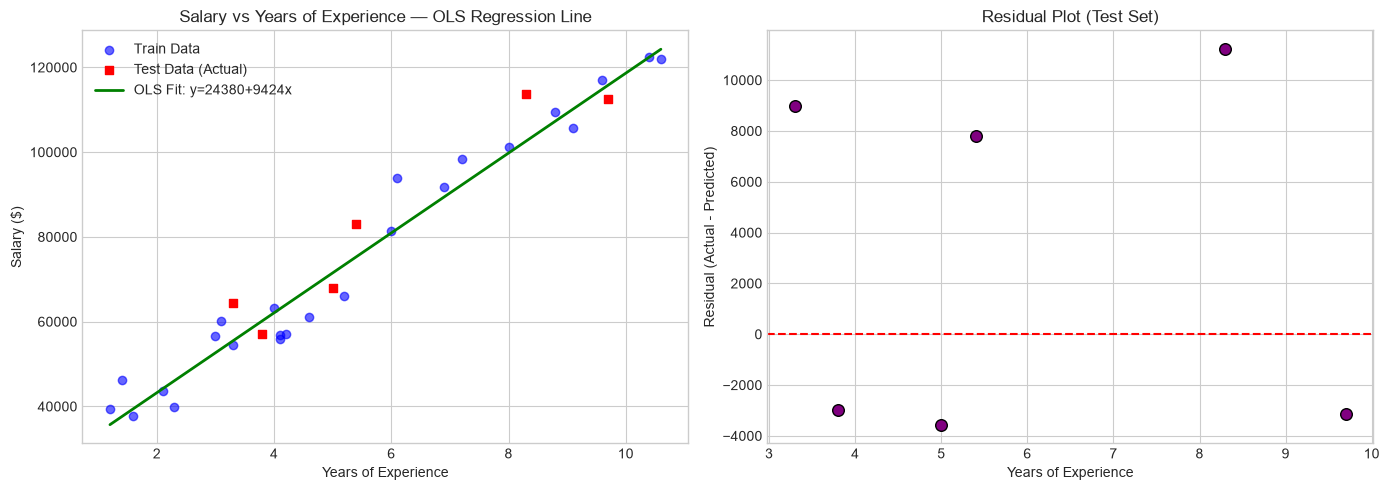

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Regression Fit
axes[0].scatter(X_train['YearsExperience'], y_train, color='blue', alpha=0.6, label='Train Data')
axes[0].scatter(X_test['YearsExperience'], y_test, color='red', marker='s', label='Test Data (Actual)')

# Full regression line
x_vals = np.linspace(df['YearsExperience'].min(), df['YearsExperience'].max(), 100).reshape(-1, 1)
axes[0].plot(x_vals, model.predict(x_vals), color='green', linewidth=2, label=f'OLS Fit: y={sklearn_beta0:.0f}+{sklearn_beta1:.0f}x')
axes[0].set_title("Salary vs Years of Experience — OLS Regression Line", fontsize=12)
axes[0].set_xlabel("Years of Experience")
axes[0].set_ylabel("Salary ($)")
axes[0].legend()

# Plot 2: Residual Plot
residuals = y_test.values - y_predict
axes[1].scatter(X_test['YearsExperience'], residuals, color='purple', s=70, edgecolor='black')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title("Residual Plot (Test Set)", fontsize=12)
axes[1].set_xlabel("Years of Experience")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()
